# VGG16 Transfer Learning on Flower Dataset with Multiple Classes

This notebook demonstrates how to use **Transfer Learning** with **VGG16** for an image classification task involving **more than 2 classes**. It uses Keras and TensorFlow for implementation.

The steps include:
- Loading a multi-class Flowers image dataset
- Preprocessing the data
- Creating the transfer learning model with VGG16
- Training, evaluation, and accuracy/loss plotting
- Inference on a new image


## Necessary Imports

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


## Downloading & Unzipping Dataset

In [ ]:
import os
import tarfile
import urllib.request

# Step 1: Define URL and local paths
url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
dataset_dir = "flower_photos"
tgz_path = "flower_photos.tgz"

# Step 2: Download the dataset if not already downloaded
if not os.path.exists(tgz_path):
    print("Downloading dataset...")
    urllib.request.urlretrieve(url, tgz_path)
    print("Download completed!")

# Step 3: Extract the .tgz file
if not os.path.exists(dataset_dir):
    print("Extracting dataset...")
    with tarfile.open(tgz_path, "r:gz") as tar:
        tar.extractall()
    print("Extraction completed!")

# Step 4: Preview classes
print("Available classes:", os.listdir(dataset_dir))

Download completed!
Extracting dataset...
Extraction completed!
Available classes: ['dandelion', 'sunflowers', 'LICENSE.txt', 'daisy', 'roses', 'tulips']


## Performing Dataset Split

In [ ]:
import os, shutil
from sklearn.model_selection import train_test_split

original_dir = "flower_photos"
base_dir = "dataset"
os.makedirs(base_dir, exist_ok=True)

for class_name in os.listdir(original_dir):
    class_path = os.path.join(original_dir, class_name)
    if not os.path.isdir(class_path): continue

    images = os.listdir(class_path)
    train, temp = train_test_split(images, test_size=0.3, random_state=42)
    val, test = train_test_split(temp, test_size=0.5, random_state=42)

    for split, split_data in zip(["train", "val", "test"], [train, val, test]):
        split_path = os.path.join(base_dir, split, class_name)
        os.makedirs(split_path, exist_ok=True)
        for img in split_data:
            shutil.copy(os.path.join(class_path, img), os.path.join(split_path, img))

### Dataset Info with Train, Test & Valid Data

In [ ]:
import os
from PIL import Image
from collections import defaultdict

def count_images_and_check_dims(root_dir):
    print(f"Scanning directory: {root_dir}")
    class_counts = defaultdict(int)
    dimensions = []

    for class_name in os.listdir(root_dir):
        class_path = os.path.join(root_dir, class_name)
        if not os.path.isdir(class_path):
            continue

        for img_name in os.listdir(class_path):
            img_path = os.path.join(class_path, img_name)
            try:
                with Image.open(img_path) as img:
                    class_counts[class_name] += 1
                    dimensions.append(img.size + (len(img.getbands()),))  # (width, height, channels)
            except Exception as e:
                print(f"Error reading {img_path}: {e}")

    print("\n📊 Image Counts per Class:")
    for class_name, count in class_counts.items():
        print(f" - {class_name}: {count} images")


# Example usage:
print("=== Train Folder ===")
count_images_and_check_dims("dataset/train")

print("\n=== Validation Folder ===")
count_images_and_check_dims("dataset/val")

print("\n=== Test Folder ===")
count_images_and_check_dims("dataset/test")

=== Train Folder ===
Scanning directory: dataset/train

📊 Image Counts per Class:
 - dandelion: 628 images
 - sunflowers: 489 images
 - daisy: 443 images
 - roses: 448 images
 - tulips: 559 images

=== Validation Folder ===
Scanning directory: dataset/val

📊 Image Counts per Class:
 - dandelion: 135 images
 - sunflowers: 105 images
 - daisy: 95 images
 - roses: 96 images
 - tulips: 120 images

=== Test Folder ===
Scanning directory: dataset/test

📊 Image Counts per Class:
 - dandelion: 135 images
 - sunflowers: 105 images
 - daisy: 95 images
 - roses: 97 images
 - tulips: 120 images


In [ ]:
!pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 59.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 84.0 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.11.0.86
    Uninstalling opencv-python-headless-4.11.0.86:
      Successfully uninstalled opencv-python-headless-4.11.0.86
  Attempting uninstall: idna
    Found existing installation: idna 3.10
    Uninstalling idna-3.10:
      Successfully uninstalled idna-3.10


In [ ]:


from roboflow import Roboflow
rf = Roboflow(api_key="OW0NGyO0XjTOUAZ7RAiE")
project = rf.workspace("ayurved").project("ayurved")
version = project.version(2)
dataset = version.download("folder")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Ayurved-2 in folder:: 100%|██████████| 1725/1725 [00:00<00:00, 8962.90it/s]


## Setting the Image Directory paths with Data Augmentation

In [ ]:
train_dir = 'dataset/train'
val_dir = 'dataset/valid'
test_dir = 'dataset/test'

img_size = (224, 224)
batch_size = 64
num_classes = len(os.listdir(train_dir))

train_datagen = ImageDataGenerator(preprocessing_function=preprocess_input, horizontal_flip=True, zoom_range=0.2)
val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(train_dir, target_size=img_size, batch_size=batch_size, class_mode='categorical')
val_generator = val_datagen.flow_from_directory(val_dir, target_size=img_size, batch_size=batch_size, class_mode='categorical')
test_generator = test_datagen.flow_from_directory(test_dir, target_size=img_size, batch_size=1, class_mode='categorical', shuffle=False)


Found 1428 images belonging to 6 classes.
Found 179 images belonging to 6 classes.
Found 100 images belonging to 1 classes.


## Defining the Model Architecture

In [ ]:
base_model = VGG16(include_top=False, weights='imagenet', input_shape=(224, 224, 3))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [ ]:
base_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
for layer in base_model.layers:
    layer.trainable = False
    print(layer)

<InputLayer name=input_layer, built=True>
<Conv2D name=block1_conv1, built=True>
<Conv2D name=block1_conv2, built=True>
<MaxPooling2D name=block1_pool, built=True>
<Conv2D name=block2_conv1, built=True>
<Conv2D name=block2_conv2, built=True>
<MaxPooling2D name=block2_pool, built=True>
<Conv2D name=block3_conv1, built=True>
<Conv2D name=block3_conv2, built=True>
<Conv2D name=block3_conv3, built=True>
<MaxPooling2D name=block3_pool, built=True>
<Conv2D name=block4_conv1, built=True>
<Conv2D name=block4_conv2, built=True>
<Conv2D name=block4_conv3, built=True>
<MaxPooling2D name=block4_pool, built=True>
<Conv2D name=block5_conv1, built=True>
<Conv2D name=block5_conv2, built=True>
<Conv2D name=block5_conv3, built=True>
<MaxPooling2D name=block5_pool, built=True>


In [ ]:
base_model.output

<KerasTensor shape=(None, 7, 7, 512), dtype=float32, sparse=False, name=keras_tensor_18>

In [ ]:
base_model.input

<KerasTensor shape=(None, 224, 224, 3), dtype=float32, sparse=False, name=keras_tensor>

In [ ]:
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)
model.compile(optimizer=Adam(learning_rate=1e-4), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         3,078 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,980,422 (57.15 MB)

 Trainable params: 265,734 (1.01 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

## Let's Start the Training

In [ ]:
callbacks = [
    EarlyStopping(patience=5, restore_best_weights=True),
    ModelCheckpoint("vgg16_best_model_ayurved.keras", save_best_only=True)
]

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    callbacks=callbacks
)


Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.


Epoch 1/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.1532 - loss: 8.2151 - val_accuracy: 0.4134 - val_loss: 2.2851
Epoch 2/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 20s 887ms/step - accuracy: 0.3961 - loss: 4.1394 - val_accuracy: 0.6648 - val_loss: 1.2456
Epoch 3/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 20s 863ms/step - accuracy: 0.5157 - loss: 2.7567 - val_accuracy: 0.7207 - val_loss: 0.9686
Epoch 4/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 20s 852ms/step - accuracy: 0.6066 - loss: 2.0277 - val_accuracy: 0.7542 - val_loss: 0.7989
Epoch 5/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 21s 894ms/step - accuracy: 0.6645 - loss: 1.7032 - val_accuracy: 0.7933 - val_loss: 0.6624
Epoch 6/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 20s 886ms/step - accuracy: 0.6898 - loss: 1.4044 - val_accuracy: 0.8101 - val_loss: 0.5710
Epoch 7/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 21s 849ms/step - accuracy: 0.6997 - loss: 1.2817 - val_accuracy: 0.8212 - val_loss: 0.5548
Epoch 8/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 21s 892ms/step - accuracy: 0.7423 - loss: 1.0850 - val_accurac

## Accuracy & Loss Graphs

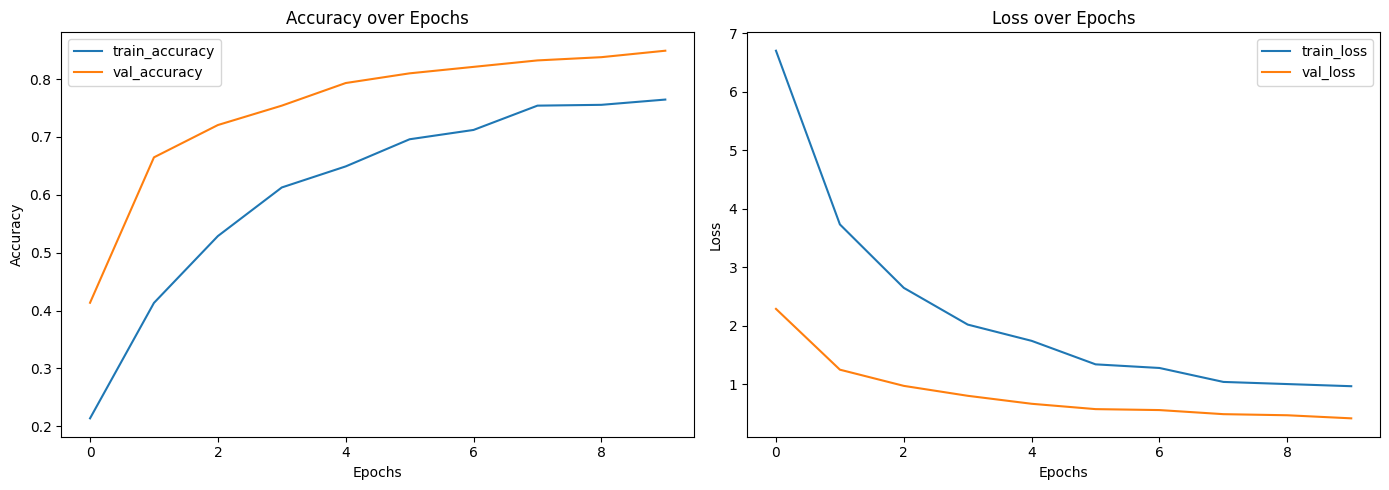

In [ ]:
def plot_history(history):
    plt.figure(figsize=(14, 5))
    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='train_accuracy')
    plt.plot(history.history['val_accuracy'], label='val_accuracy')
    plt.title('Accuracy over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='train_loss')
    plt.plot(history.history['val_loss'], label='val_loss')
    plt.title('Loss over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(history)


In [ ]:
loss, accuracy = model.evaluate(test_generator)
print(f"Test Accuracy: {accuracy:.4f}")


100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.0988 - loss: 75.5129
Test Accuracy: 0.1100


In [ ]:
def predict_image(image_path):
    img = load_img(image_path, target_size=img_size)
    plt.imshow(img) # Display the image
    plt.axis('off') # Hide axes
    plt.show() # Show the image
    img_array = img_to_array(img)
    img_array = preprocess_input(np.expand_dims(img_array, axis=0))
    pred = model.predict(img_array)
    predicted_class = np.argmax(pred)
    class_names = list(train_generator.class_indices.keys())
    print(f"Predicted Class: {class_names[predicted_class]}")

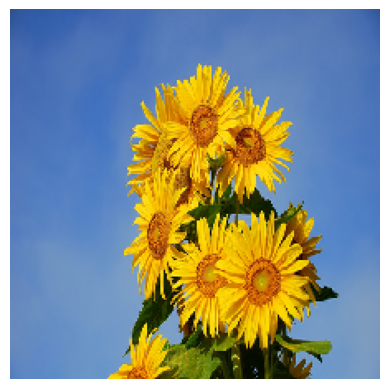

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 643ms/step
Predicted Class: sunflowers


In [ ]:
predict_image('/content/dataset/test/sunflowers/1297092593_e573c0a3d6.jpg')

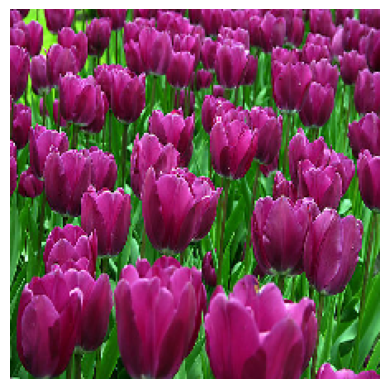

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
Predicted Class: tulips


In [ ]:
predict_image('/content/dataset/test/tulips/11746276_de3dec8201.jpg')

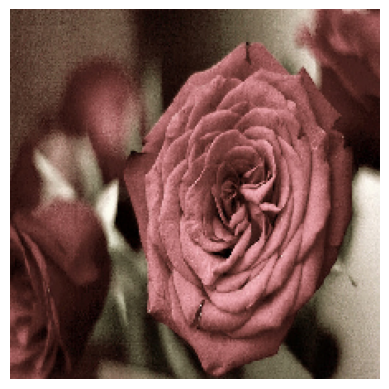

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
Predicted Class: roses


In [ ]:
predict_image('/content/dataset/test/roses/12202373204_34fb07205b.jpg')

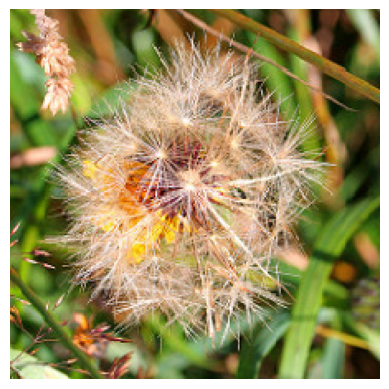

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
Predicted Class: dandelion


In [ ]:
predict_image('/content/dataset/test/dandelion/1273326361_b90ea56d0d_m.jpg')

In [ ]:
!pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 103.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 105.6 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.11.0.86
    Uninstalling opencv-python-headless-4.11.0.86:
      Successfully uninstalled opencv-python-headless-4.11.0.86
  Attempting uninstall: idna
    Found existing installation: idna 3.10
    Uninstalling idna-3.10:
      Successfully uninstalled idna-3.10


In [ ]:


from roboflow import Roboflow
rf = Roboflow(api_key="OW0NGyO0XjTOUAZ7RAiE")
project = rf.workspace("ayurved").project("ayurved")
version = project.version(2)
dataset = version.download("folder")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Ayurved-2 in folder:: 100%|██████████| 1725/1725 [00:00<00:00, 3545.69it/s]
